# 14 - PatchCore ecrit a la main : la reference des anomalies, sans entrainement

PatchCore decrit chaque zone d'une image par un vecteur (couches intermediaires d'un ResNet18
pre-entraine et gele), memorise les vecteurs des pieces BONNES, puis juge une nouvelle piece :
une zone dont le vecteur est loin de tous les vecteurs memorises est anormale. Aucun
entrainement, aucun defaut necessaire pour construire le modele.

Ce que tu vas voir, tout le code etant ecrit dans ce notebook :
1. le protocole des anomalies : que des normales en train et val, des defauts seulement en test ;
2. l'extracteur de caracteristiques locales (resnet18 gele, voisinage 3x3) ;
3. la banque memoire et sa reduction par coreset glouton (k-center) ;
4. la distance au plus proche voisin ecrite en produits matriciels (exportable partout) ;
5. la carte d'anomalie, le score image, le seuil calibre sur les normales de validation ;
6. l'effet de la taille de la memoire ; l'export ONNX en un bloc (memoire dans le graphe).

Prerequis : le socle de la toolbox (torch, torchvision, opencv, onnx, onnxruntime, scikit-learn)
et les donnees `python tools/get_data/get_mvtec_bottle.py` (MVTec AD bottle, CC BY-NC-SA 4.0,
usage non commercial). Les poids ImageNet du resnet18 viennent du cache torchvision.

Duree en mode QUICK sur un CPU 2 coeurs : environ 5 minutes.

**Le fil** (memes etapes que le cours et que `ETAPES.md`, a la racine de la toolbox) :

```
1 Imports et reglages -> 3 Cataloguer -> 4 Decouper -> 5 Pretraiter
  -> 8 Modele (extracteur gele) -> 10 Entrainer (ici : remplir la memoire, sans gradient)
  -> 8 Modele (complet) -> 11 Evaluer (seuil sur les normales de validation, puis le test)
  -> 9 Hyperparametres (taille de la memoire) -> 12 Sauvegarder et exporter
  -> 13 Predire (dans "Passer en production")
```

PatchCore n'a ni augmentation (6), ni lots melanges (7), ni perte ni optimiseur : rien ne
s'apprend par gradient, et de l'etape 9 il ne reste qu'un hyperparametre, la taille de la
memoire. L'etape 2 (importer et explorer) est dans les notebooks 00, 01 et 05.

## Etape 1 - Imports et reglages

Une seule cellule : les imports, puis le bloc REGLAGES (tout ce qu'on change pour ses propres
donnees est la, et seulement la), le dossier de sortie et la graine du hasard.

In [1]:
import json  # json : ecrit la carte du modele dans un fichier texte lisible
import time  # time : chronometre les etapes et date la carte du modele
import warnings  # warnings : masque les avertissements sans importance
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import cv2  # OpenCV : lecture, ecriture et traitement d'images
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
import onnxruntime as ort  # onnxruntime : execute un modele au format ONNX (format d'echange, sans PyTorch)
import pandas as pd  # pandas : tableaux de donnees (une ligne par image) faciles a filtrer et a grouper
import torch  # PyTorch : calcul sur des tenseurs (tableaux de nombres a plusieurs dimensions) et reseaux de neurones
import torch.nn as nn  # nn : briques des reseaux de neurones (couches, modules)
import torch.nn.functional as F  # F : fonctions de calcul sans poids (interpolation, moyenne locale, convolution...)
from IPython.display import display  # display : affiche joliment un tableau dans le notebook
from sklearn.metrics import f1_score, roc_auc_score  # metriques : F1 (rappel et precision combines) et AUROC (qualite du classement)
from sklearn.model_selection import train_test_split  # tire au hasard une partie des lignes (pour la validation)
from torchvision import models  # models : reseaux connus (resnet18...) avec leurs poids pre-entraines

from vtb import viz  # viz : affichage de la boite a outils (grilles d'images, courbes, tableaux)

# ---- REGLAGES : tout ce qu'on change pour ses propres donnees ------------------------------
QUICK = True  # True : etude de la memoire reduite (CPU) ; False : etude complete
DATA_DIR = Path("data/raw/mvtec_bottle")  # rangement MVTec : train/good, test/<type>, ground_truth/<type>/<nom>_mask.png
COLOR = "rgb"  # "gray" pour des images en niveaux de gris (acier) : copiees sur 3 canaux dans le modele
IMAGE_SIZE = 256  # cote apres resize ; les cartes d'anomalie ont cette taille
LAYERS = ["layer2", "layer3"]  # detail (layer2, pas de 8 pixels) + contexte (layer3, pas de 16)
MEMORY_FRACTION = 0.02  # part des vecteurs normaux gardes par le coreset (la recette : 2 %)
VAL_FRACTION = 0.15  # normales du train mises de cote pour calibrer le seuil
SIGMA = 4.0  # lissage gaussien de la carte, en pixels
IMAGE_QUANTILE, PIXEL_QUANTILE = 0.99, 0.999  # seuils = quantiles des normales de validation (0,99 : 1 % des normales au-dessus)
BATCH_SIZE = 16  # images traitees ensemble a chaque passage (un lot, ou batch) : plus grand = plus de memoire
SEED = 42  # graine du hasard : memes tirages a chaque execution, resultats reproductibles
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # calcul sur la carte graphique (GPU) si presente, sinon CPU
OUT = Path("outputs/notebooks/14_anomalies_patchcore")  # dossier ou ce notebook ecrit ses resultats
# --------------------------------------------------------------------------------------------

OUT.mkdir(parents=True, exist_ok=True)  # cree le dossier de sortie (et ses parents) s'il n'existe pas encore
torch.manual_seed(SEED)  # fixe le hasard de PyTorch : resultats reproductibles
warnings.filterwarnings("ignore", category=UserWarning)  # masque les avertissements d'usage qui encombrent l'affichage
viz.setup_notebook(dpi=80, fmt="jpeg")  # figures en resolution moderee et en jpeg : notebook plus leger
print("device :", DEVICE, "| torch", torch.__version__)  # affiche le materiel et la version de PyTorch

device : cpu | torch 2.15.0+cu132


## Etapes 3 et 4 - Cataloguer et decouper : aucun defaut ne sert a construire le modele

Trois regles, qui valent pour toutes les methodes d'anomalies :
- **train** : des normales seulement (c'est ce que le modele apprend) ;
- **val** : des normales seulement ; elles fixent le seuil (on accepte 1 % de fausses alarmes) ;
- **test** : le reste des normales et TOUS les defauts ; il n'est lu qu'une fois, a la fin.

MVTec fournit deja train (normales) et test (normales + defauts) : on preleve la validation dans
le train, avec le meme algorithme et la meme graine que la recette (meme decoupage, donc memes
chiffres).

In [2]:
IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")  # extensions reconnues comme images


def list_images(folder: Path) -> list[Path]:  # renvoie la liste triee des images d'un dossier et de ses sous-dossiers
    """Images d'un dossier, triees : l'ordre du disque differe entre Windows et Linux."""
    # tous les fichiers (rglob = recherche dans les sous-dossiers aussi) dont l'extension est une extension d'image
    return sorted(p for p in Path(folder).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)


def mvtec_catalog(root: Path) -> pd.DataFrame:  # catalogue d'un dossier MVTec ; renvoie un tableau pandas
    """Une ligne par image : chemin, good / defect, type de defaut, rangement d'origine, masque (vide pour une normale)."""
    rows = [  # d'abord les images d'entrainement : toutes bonnes ("good")
        {"path": str(p), "label": "good", "defect_type": "good", "split": "train", "mask_path": ""}  # pas de masque : piece bonne
        for p in list_images(root / "train" / "good")  # pour chaque image de train/good
    ]
    for type_dir in sorted(d for d in (root / "test").iterdir() if d.is_dir()):  # pour chaque sous-dossier de test (good, broken...)
        for p in list_images(type_dir):  # pour chaque image de ce type
            mask = root / "ground_truth" / type_dir.name / f"{p.stem}_mask.png"  # chemin de son masque de verite (s'il existe)
            rows.append(  # ajoute la ligne de cette image
                {  # une ligne du tableau
                    "path": str(p),  # chemin de l'image
                    "label": "good" if type_dir.name == "good" else "defect",  # etiquette image : bonne ou defaut
                    "defect_type": type_dir.name,  # type precis (nom du sous-dossier)
                    "split": "test",  # tout le dossier test va au test
                    "mask_path": str(mask) if mask.exists() else "",  # chemin du masque, vide s'il n'y en a pas
                }
            )
    return pd.DataFrame(rows)  # renvoie le catalogue


def anomaly_split(catalog: pd.DataFrame, val_fraction: float, seed: int) -> pd.DataFrame:  # preleve la validation ; renvoie le catalogue
    """Normales du train -> train / val ; le test (normales + defauts) reste le test."""
    catalog = catalog.copy().reset_index(drop=True)  # copie renumerotee : l'original n'est pas modifie
    pool = catalog[(catalog["label"] == "good") & (catalog["split"] == "train")]  # normales d'entrainement (& = ET logique)
    _, val = train_test_split(pool, test_size=val_fraction, random_state=seed)  # 15 % d'entre elles tirees au hasard (graine fixe)
    catalog.loc[val.index, "split"] = "val"  # ... et marquees "val"
    leaked = catalog[(catalog["split"] != "test") & (catalog["label"] != "good")]  # defauts hors du test (il ne doit y en avoir aucun)
    assert leaked.empty, f"{len(leaked)} defauts dans train / val : un detecteur d'anomalies n'apprend que le normal"  # controle
    return catalog  # renvoie le catalogue decoupe


split = anomaly_split(mvtec_catalog(DATA_DIR), VAL_FRACTION, SEED)  # catalogue MVTec bottle decoupe en train / val / test
split.to_csv(OUT / "split.csv", index=False)  # sauvegarde le decoupage
display(pd.crosstab(split["defect_type"], split["split"], margins=True))  # nombre d'images par type et par partie, avec totaux

split,test,train,val,All
defect_type,,,,
broken_large,20,0,0,20
broken_small,22,0,0,22
contamination,21,0,0,21
good,20,177,32,229
All,83,177,32,292


## Etape 5 - Pretraiter : lire les images, la meme lecture et le meme resize qu'en production

- lecture par `np.fromfile` + `cv2.imdecode` : `cv2.imread` echoue en silence sur un chemin
  Windows avec accents ; OpenCV lit en BGR, on passe en RGB une seule fois ;
- resize en INTER_AREA quand on reduit (pas de moirage sur les textures fines), INTER_LINEAR
  quand on agrandit : c'est l'operation `resize` de la toolbox, celle que la carte du modele
  decrit au programme de production ;
- le masque suit au PLUS PROCHE VOISIN (une interpolation creerait des valeurs entre 0 et 1).

Toutes les images tiennent en memoire (300 images de 256 x 256 : 60 Mo) : on les lit une fois.

lecture : 5 s | train (177, 3, 256, 256) | val (32, 3, 256, 256) | test (83, 3, 256, 256)


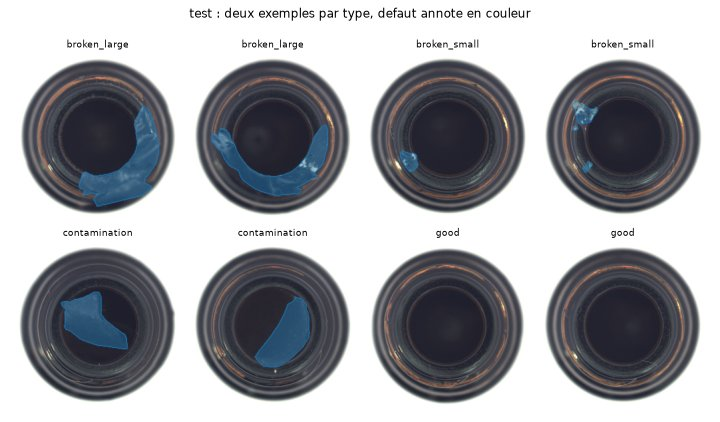

In [3]:
def read_image(path: str | Path, color: str = "rgb") -> np.ndarray:  # lit une image ; renvoie RGB (H, W, 3) ou gris (H, W)
    """RGB (H, W, 3) ou gris (H, W), uint8 ou uint16 conserve ; robuste aux chemins Windows."""
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_UNCHANGED)  # octets du fichier -> image, sans conversion
    if image is None:  # None = le fichier n'est pas une image lisible
        raise ValueError(f"image illisible : {path}")  # arret avec un message clair
    if image.ndim == 3 and image.shape[2] == 4:  # si l'image a 4 canaux (couleur + transparence "alpha")
        image = image[:, :, :3]  # canal alpha ignore : on garde les 3 canaux de couleur
    if color == "gray":  # si on veut du gris
        return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if image.ndim == 3 else image  # couleur -> gris ; deja gris : inchange
    # sinon RGB : une image grise est copiee sur 3 canaux ; une image couleur passe de BGR (ordre OpenCV) a RGB
    return np.stack([image] * 3, axis=-1) if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def resize(image: np.ndarray, size: int) -> np.ndarray:  # redimensionne une image en carre size x size
    """Carre size x size : INTER_AREA pour reduire, INTER_LINEAR pour agrandir (operation `resize` de la toolbox)."""
    shrinking = size * size < image.shape[0] * image.shape[1]  # vrai si l'image est reduite (moins de pixels a l'arrivee)
    # INTER_AREA (moyenne des pixels) pour reduire, interpolation lineaire pour agrandir
    return cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA if shrinking else cv2.INTER_LINEAR)


def read_mask(path: str, size: int) -> np.ndarray:  # lit un masque de verite en 0/1 a la taille du modele
    """Masque 0 / 1 a la taille du modele ; une image sans masque (normale) donne un masque vide."""
    if not path:  # chemin vide : image sans masque (piece normale)
        return np.zeros((size, size), np.uint8)  # masque tout a 0 : aucun pixel de defaut
    mask = (read_image(path, "gray") > 127).astype(np.uint8)  # 127 : ignore les bords anti-creneles des PNG ; blanc -> 1
    return cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)  # plus proche voisin : chaque pixel reste 0 ou 1


def to_tensor(images: np.ndarray) -> torch.Tensor:  # tableau d'images numpy -> tenseur (N, C, H, W) dans [0, 1]
    """(N, H, W) ou (N, H, W, 3) -> (N, C, H, W) float32 dans [0, 1]. La normalisation ImageNet est DANS le modele."""
    peak = 65535.0 if images.dtype == np.uint16 else 255.0  # valeur maximale possible : 65535 en 16 bits, 255 en 8 bits
    x = torch.from_numpy(images.astype(np.float32) / peak)  # tenseur de nombres a virgule dans [0, 1]
    return x[:, None] if x.ndim == 3 else x.permute(0, 3, 1, 2).contiguous()  # ajoute l'axe canal (gris) ou le met devant (couleur)


def load_subset(name: str) -> tuple[pd.DataFrame, np.ndarray, np.ndarray]:  # lit une partie ; renvoie (tableau, images, masques)
    frame = split[split["split"] == name].reset_index(drop=True)  # lignes de cette partie (train, val ou test), renumerotees
    images = np.stack([resize(read_image(p, COLOR), IMAGE_SIZE) for p in frame["path"]])  # images lues, redimensionnees, empilees
    masks = np.stack([read_mask(m, IMAGE_SIZE) for m in frame["mask_path"]])  # masques empiles (N, H, W)
    return frame, images, masks  # tableau, images et masques de la partie


start = time.time()  # chrono de la lecture
train_df, train_images, _ = load_subset("train")  # normales d'entrainement : remplissent la memoire (masques inutiles : _)
val_df, val_images, _ = load_subset("val")  # normales de validation : fixent le seuil
test_df, test_images, test_masks = load_subset("test")  # test : normales + defauts, avec leurs masques
x_train, x_val, x_test = to_tensor(train_images), to_tensor(val_images), to_tensor(test_images)  # images en tenseurs (N, C, H, W)
test_labels = (test_df["label"] == "defect").to_numpy().astype(int)  # verite par image du test : 1 = defaut, 0 = normale
# duree de lecture et formes des tenseurs
print(f"lecture : {time.time() - start:.0f} s | train {tuple(x_train.shape)} | val {tuple(x_val.shape)} | test {tuple(x_test.shape)}")

examples = test_df.groupby("defect_type").head(2).index.tolist()  # deux images du test par type (good compris)
viz.grid(  # affiche plusieurs images cote a cote dans une grille
    [viz.overlay_mask(test_images[i], test_masks[i], alpha=0.45) for i in examples],  # image + masque de verite colore par-dessus
    [test_df.loc[i, "defect_type"] for i in examples],  # titres : le type de chaque image
    ncols=4,  # 4 images par ligne
    size=2.2,  # largeur de chaque colonne (pouces)
    suptitle="test : deux exemples par type, defaut annote en couleur",  # titre general
)

## Etape 8 - Modele : decrire chaque zone, les couches intermediaires d'un resnet18 gele

- `layer2` (pas de 8 pixels, 128 canaux) voit le detail, `layer3` (pas de 16, 256 canaux) le
  contexte. On remonte `layer3` a la resolution de `layer2` et on concatene : 384 valeurs par
  zone, sur une grille 32 x 32 pour une image de 256.
- Une moyenne 3 x 3 (avg_pool) fait decrire a chaque vecteur un voisinage, pas un point : le
  score devient robuste a un decalage d'un pixel.
- Pourquoi pas `layer4` : trop specialise sur les classes d'ImageNet et trop grossier (pas de 32).
- La normalisation ImageNet est faite DANS le module : le programme de production envoie une
  image dans [0, 1], rien d'autre. Une image grise est copiee sur 3 canaux, la aussi dans le module.

In [4]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # moyenne et ecart-type par canal (R, G, B) d'ImageNet


class PatchFeatures(nn.Module):  # extracteur : decrit chaque zone de l'image par un vecteur (caracteristiques locales)
    """Image (N, C, S, S) dans [0, 1] -> caracteristiques locales (N, D, S/8, S/8), resnet18 gele."""

    def __init__(self, layers: list[str]) -> None:  # construit l'extracteur ; layers = couches dont on garde la sortie
        super().__init__()  # initialise la partie nn.Module (obligatoire pour enregistrer les couches)
        backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT).eval()  # resnet18 avec ses poids ImageNet, mode evaluation
        # tronc d'entree du resnet : convolution, BatchNorm, ReLU, maxpool (resolution divisee par 4)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        # les 4 etages du resnet, ranges par nom (getattr lit l'attribut qui porte ce nom)
        self.blocks = nn.ModuleDict({name: getattr(backbone, name) for name in ("layer1", "layer2", "layer3", "layer4")})
        self.layers = layers  # couches retenues (layer2, layer3)
        # buffer : constante rangee dans le modele (sauvee et exportee avec lui) ; forme (1, 3, 1, 1) pour agir canal par canal
        self.register_buffer("mean", torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(IMAGENET_STD).view(1, 3, 1, 1))  # ecart-type ImageNet, meme principe
        for p in self.parameters():  # pour chaque poids du reseau
            p.requires_grad = False  # gele : rien n'est appris (pas de gradient a calculer)

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # renvoie les vecteurs de toutes les zones (N, D, h, w)
        if x.shape[1] == 1:  # si l'image n'a qu'un canal (gris)
            x = x.repeat(1, 3, 1, 1)  # image grise -> 3 canaux identiques (poids ImageNet exacts)
        x = self.stem((x - self.mean) / self.std)  # normalisation ImageNet (centrer, reduire) puis tronc d'entree
        outputs = {}  # sortie de chaque etage, par nom
        for name, block in self.blocks.items():  # pour chaque etage, dans l'ordre (layer1, layer2...)
            x = block(x)  # passe dans l'etage
            outputs[name] = x  # garde sa sortie
            if name == self.layers[-1]:  # si c'est la derniere couche retenue
                break  # inutile de calculer les couches suivantes
        target = outputs[self.layers[0]].shape[-2:]  # resolution de la premiere couche retenue (la plus fine)
        # liste des caracteristiques : celles de la couche fine (layer2), puis celles des couches plus grossieres ...
        feats = [outputs[self.layers[0]]] + [
            # ... remontees a la resolution de la couche fine (interpolation bilineaire)
            F.interpolate(outputs[n], size=target, mode="bilinear", align_corners=False)
            for n in self.layers[1:]  # pour chaque couche retenue apres la premiere (ici layer3)
        ]
        # colle les canaux (128 + 256 = 384) puis moyenne 3 x 3 : chaque vecteur decrit un petit voisinage
        return F.avg_pool2d(torch.cat(feats, dim=1), 3, stride=1, padding=1)


features = PatchFeatures(LAYERS).to(DEVICE).eval()  # l'extracteur, sur GPU ou CPU, en mode evaluation
with torch.no_grad():  # sans calcul de gradient : simple passage
    sample = features(x_train[:1].to(DEVICE))  # caracteristiques d'une image, pour voir leur forme
print(  # affiche la transformation : image -> grille de vecteurs
    "une image",  # texte
    tuple(x_train[:1].shape),  # forme de l'entree (1, 3, 256, 256)
    "->",  # fleche
    tuple(sample.shape),  # forme de la sortie (1, 384, 32, 32)
    f"= {sample.shape[2] * sample.shape[3]} vecteurs de {sample.shape[1]} valeurs",  # nombre de zones et taille d'un vecteur
)

une image (1, 3, 256, 256) -> (1, 384, 32, 32) = 1024 vecteurs de 384 valeurs


## Etape 10 - Entrainer : la banque memoire et le coreset glouton

"Entrainer" veut dire ici remplir une memoire : aucun gradient, aucune epoque.

Tous les vecteurs de toutes les normales d'entrainement forment la banque (177 images x 1 024
zones = 181 000 vecteurs). Tout garder rendrait chaque prediction lente (une distance a 181 000
vecteurs par zone). Le coreset k-center glouton garde un petit sous-ensemble qui COUVRE la
banque : a chaque pas, il ajoute le vecteur le plus eloigne de ceux deja choisis. Un tirage
aleatoire, lui, garde surtout les zones frequentes (le fond) et rate les zones rares mais
normales (le bord du goulot), qui deviennent alors des fausses alarmes.

Deux astuces de calcul (celles de la toolbox) :
- la selection travaille dans une projection aleatoire a 128 dimensions (Johnson-Lindenstrauss :
  les distances sont presque conservees, le calcul est 3 fois plus court) ;
- la distance au carre s'ecrit |x|^2 - 2 x.c + |c|^2 : un produit matrice-vecteur par pas.

In [5]:
@torch.no_grad()  # pas de calcul de gradient dans cette fonction : plus rapide, moins de memoire
def extract_bank(x: torch.Tensor) -> torch.Tensor:  # renvoie tous les vecteurs locaux des images, un par ligne
    """Tous les vecteurs locaux d'un lot d'images : (N x h x w, D)."""
    chunks = []  # morceaux de la banque, lot par lot
    for i in range(0, len(x), BATCH_SIZE):  # pour chaque lot de BATCH_SIZE images
        f = features(x[i : i + BATCH_SIZE].to(DEVICE))  # caracteristiques du lot (n, D, h, w)
        # (n, D, h, w) -> (n, h, w, D) -> (n x h x w, D) : une ligne par zone ; ramene sur CPU
        chunks.append(f.permute(0, 2, 3, 1).reshape(-1, f.shape[1]).cpu())
    return torch.cat(chunks)  # recolle tous les morceaux en une seule banque


# renvoie les indices des n vecteurs gardes par le coreset glouton
def greedy_coreset(vectors: torch.Tensor, n: int, seed: int, projection_dim: int = 128) -> torch.Tensor:
    """Indices d'un coreset k-center glouton : a chaque pas, le vecteur le plus loin de ceux deja choisis."""
    generator = torch.Generator().manual_seed(seed)  # generateur de hasard dedie, graine fixe
    if vectors.shape[1] > projection_dim:  # si les vecteurs ont plus de 128 dimensions
        # matrice aleatoire (D, 128) ; la division garde les distances a la meme echelle
        projection = torch.randn(vectors.shape[1], projection_dim, generator=generator) / projection_dim**0.5
        reduced = vectors @ projection  # projection : chaque vecteur passe a 128 dimensions (@ = produit matriciel)
    else:  # sinon (deja petits)
        reduced = vectors  # on garde les vecteurs tels quels
    squared = (reduced * reduced).sum(dim=1)  # |x|^2 de chaque vecteur, calcule une seule fois

    def distance_to(i: int) -> torch.Tensor:  # distance au carre de tous les vecteurs au vecteur i
        # |x|^2 - 2 x.c + |c|^2 ; clamp_min_ remplace les petits negatifs (erreurs d'arrondi) par 0
        return (squared - 2 * (reduced @ reduced[i]) + squared[i]).clamp_min_(0)

    selected = [int(torch.randint(len(reduced), (1,), generator=generator))]  # premier vecteur au hasard
    distances = distance_to(selected[0])  # distance de chaque vecteur au plus proche choisi
    for _ in range(n - 1):  # ajoute les n - 1 vecteurs suivants, un par pas
        index = int(distances.argmax())  # le vecteur le plus loin de tous ceux deja choisis
        selected.append(index)  # on le garde
        torch.minimum(distances, distance_to(index), out=distances)  # met a jour la distance au plus proche choisi (sur place)
    return torch.tensor(selected)  # indices choisis, en tenseur


start = time.time()  # chrono de l'extraction
bank = extract_bank(x_train)  # la banque : tous les vecteurs de toutes les normales d'entrainement
print(f"banque : {tuple(bank.shape)} ({bank.numel() * 4 / 1e6:.0f} Mo) en {time.time() - start:.0f} s")  # taille (4 octets/valeur)
start = time.time()  # chrono du coreset
keep = greedy_coreset(bank, max(1, int(MEMORY_FRACTION * len(bank))), SEED)  # indices des 2 % de vecteurs qui couvrent la banque
memory = bank[keep].contiguous()  # la memoire : seulement ces vecteurs, ranges d'un bloc
print(f"coreset glouton : {len(memory)} vecteurs ({MEMORY_FRACTION:.0%}) en {time.time() - start:.0f} s")  # taille et duree

banque : (181248, 384) (278 Mo) en 5 s


coreset glouton : 3624 vecteurs (2%) en 16 s


## Etape 8 - Modele : le modele complet (distance au plus proche voisin, carte lissee, score image)

- Distance de chaque zone a la memoire : |a - b|^2 = |a|^2 - 2 a.b + |b|^2, puis minimum sur la
  memoire. Que des produits matriciels : pas de `cdist`, l'ONNX passe dans tous les moteurs.
- La carte brute (32 x 32) est remontee a 256 x 256 (bilineaire) puis lissee (gaussienne,
  sigma 4) : un pixel isole ne suffit plus a declencher.
- Score image = maximum de la carte : une seule zone anormale suffit a rejeter la piece.

Les trois etapes forment UN `nn.Module` : c'est lui qu'on exporte, memoire comprise.

In [6]:
class PatchCore(nn.Module):  # module : image -> distance de chaque zone au plus proche vecteur normal de la memoire
    """Image (N, C, S, S) dans [0, 1] -> carte brute (N, 1, h, w) : distance de chaque zone au plus proche vecteur normal."""

    def __init__(self, features: PatchFeatures, memory: torch.Tensor) -> None:  # assemble l'extracteur et la memoire
        super().__init__()  # initialise la partie nn.Module
        self.features = features  # l'extracteur gele
        self.register_buffer("memory", memory.clone())  # la memoire, rangee dans le modele (elle part dans le fichier ONNX)
        self.register_buffer("memory_sq", (memory**2).sum(dim=1))  # |b|^2 de chaque vecteur memorise, calcule une fois

    def forward(self, x: torch.Tensor) -> torch.Tensor:  # renvoie la carte brute (N, 1, h, w)
        f = self.features(x)  # vecteurs des zones (N, D, h, w)
        n, c, h, w = f.shape  # nombre d'images, dimension des vecteurs, hauteur et largeur de la grille
        flat = f.permute(0, 2, 3, 1).reshape(n, h * w, c)  # (N, zones, D) : une ligne par zone
        # distance au carre de chaque zone a chaque vecteur memorise : |a|^2 - 2 a.b + |b|^2 -> (N, zones, taille memoire)
        sq = (flat**2).sum(dim=2, keepdim=True) - 2 * flat @ self.memory.t() + self.memory_sq.view(1, 1, -1)
        # plus proche voisin (minimum), negatifs d'arrondi mis a 0, racine = distance ; remise en grille (N, 1, h, w)
        return sq.amin(dim=2).clamp_min(0).sqrt().view(n, 1, h, w)


def gaussian_kernel(sigma: float) -> torch.Tensor:  # noyau de flou gaussien 2D ; renvoie un tenseur (1, 1, k, k)
    radius = max(1, int(np.ceil(3 * sigma)))  # rayon = 3 sigma (au-dela la gaussienne est quasi nulle), au moins 1
    coords = torch.arange(-radius, radius + 1, dtype=torch.float32)  # positions -rayon ... +rayon
    kernel = torch.exp(-(coords**2) / (2 * sigma**2))  # courbe en cloche (gaussienne) a une dimension
    kernel = kernel / kernel.sum()  # somme ramenee a 1 : le flou ne change pas le niveau moyen
    return torch.outer(kernel, kernel)[None, None]  # produit exterieur -> noyau 2D ; [None, None] ajoute 2 axes (forme d'un filtre)


class MapToScore(nn.Module):  # module : carte brute -> carte lissee a la taille de l'image + score image
    """Carte brute (N, 1, h, w) -> carte lissee (N, 1, S, S) et score image (N,) = maximum de la carte."""

    def __init__(self, size: int, sigma: float) -> None:  # taille de sortie et force du lissage
        super().__init__()  # initialise la partie nn.Module
        self.size = (size, size)  # taille finale de la carte (hauteur, largeur)
        # noyau range dans le modele (sauve et exporte avec lui) ; sigma = 0 : noyau neutre 1 x 1 (pas de flou)
        self.register_buffer("kernel", gaussian_kernel(sigma) if sigma > 0 else torch.ones(1, 1, 1, 1))

    def forward(self, raw: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:  # renvoie (cartes lissees, scores)
        # remonte la carte a la taille de l'image (interpolation bilineaire) si elle ne l'est pas deja
        maps = F.interpolate(raw, size=self.size, mode="bilinear", align_corners=False) if raw.shape[-2:] != self.size else raw
        radius = self.kernel.shape[-1] // 2  # rayon du noyau (0 pour le noyau neutre)
        if radius:  # si un lissage est demande
            maps = F.conv2d(F.pad(maps, (radius,) * 4, mode="reflect"), self.kernel)  # bords prolonges en miroir, puis flou (convolution)
        return maps, maps.flatten(1).amax(dim=1)  # carte lissee, et score image = valeur maximale de la carte


class AnomalyModel(nn.Module):  # modele complet : image -> (carte, score)
    """Le modele de production : image [0, 1] -> (carte d'anomalie, score)."""

    def __init__(self, raw_map: nn.Module, to_score: MapToScore) -> None:  # assemble les deux etages
        super().__init__()  # initialise la partie nn.Module
        self.raw_map, self.to_score = raw_map, to_score  # etage 1 : carte brute ; etage 2 : lissage et score

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:  # renvoie (carte lissee, score)
        return self.to_score(self.raw_map(x))  # carte brute, puis lissage et score


@torch.no_grad()  # pas de calcul de gradient
def score_images(model: nn.Module, x: torch.Tensor) -> tuple[np.ndarray, np.ndarray]:  # renvoie (scores, cartes) des images
    """Scores (N,) et cartes (N, S, S) d'un lot d'images."""
    model.eval().to(DEVICE)  # mode evaluation, sur GPU ou CPU
    scores, maps = [], []  # resultats lot par lot
    for i in range(0, len(x), BATCH_SIZE):  # pour chaque lot de BATCH_SIZE images
        m, s = model(x[i : i + BATCH_SIZE].to(DEVICE))  # cartes et scores du lot
        maps.append(m[:, 0].cpu())  # cartes sans l'axe canal, ramenees sur CPU
        scores.append(s.cpu())  # scores ramenes sur CPU
    return torch.cat(scores).numpy(), torch.cat(maps).numpy()  # tout recolle, en tableaux numpy


model = AnomalyModel(PatchCore(features, memory), MapToScore(IMAGE_SIZE, SIGMA)).eval()  # le modele complet, pret a juger

## Etape 11 - Evaluer : le seuil, un quantile des normales de VALIDATION

Le seuil image est le quantile 0,99 des scores des normales de validation : on choisit le taux
de fausses alarmes (1 %) sans avoir vu un seul defaut. Le seuil pixel (quantile 0,999 des pixels
des memes cartes) sert a compter les pixels anormaux et a dessiner les contours.

Avec 32 normales de validation, le quantile 0,99 est presque le maximum : en production, plus
de normales de validation donnent un seuil plus stable.

In [7]:
val_scores, val_maps = score_images(model, x_val)  # scores et cartes des normales de validation
thresholds = {  # les deux seuils
    "image": float(np.quantile(val_scores, IMAGE_QUANTILE)),  # seuil image : quantile 0,99 des scores des normales
    "pixel": float(np.quantile(val_maps, PIXEL_QUANTILE)),  # seuil pixel : quantile 0,999 de tous les pixels des cartes
}
# affiche les seuils et le nombre de normales qui ont servi
print(f"seuil image {thresholds['image']:.4f} | seuil pixel {thresholds['pixel']:.4f} | {len(val_scores)} normales de validation")

seuil image 1.9153 | seuil pixel 1.5397 | 32 normales de validation


## Etape 11 - Evaluer : le test, lu une seule fois

- AUROC image et pixel : qualite du classement, sans seuil ;
- au seuil calibre : rappel (defauts trouves), fausses alarmes (normales rejetees), F1 ;
- rappel par type de defaut : une moyenne cache souvent un type rate.

,valeur
auroc_image,1.000
auroc_pixel,0.982
recall,1.000
false_alarm_rate,0.000
f1,1.000
ms_per_image,53.000


rappel par type : {'broken_large': 1.0, 'broken_small': 1.0, 'contamination': 1.0}


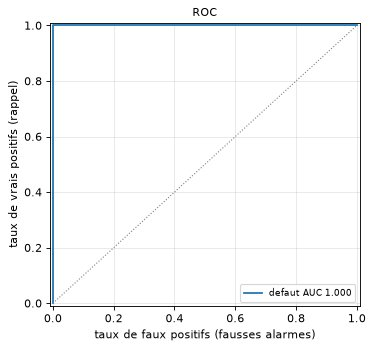

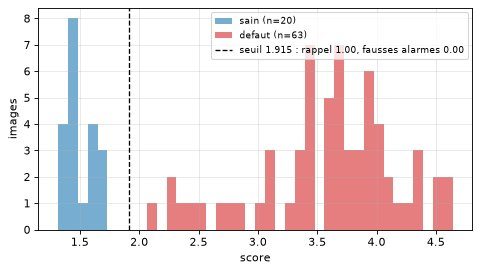

In [8]:
start = time.time()  # chrono de la prediction sur le test
test_scores, test_maps = score_images(model, x_test)  # scores et cartes de tout le test
ms_per_image = 1000 * (time.time() - start) / len(x_test)  # temps moyen par image, en millisecondes


def anomaly_metrics(  # metriques image et pixel au seuil donne
    scores: np.ndarray,  # score de chaque image (N,)
    maps: np.ndarray,  # carte d'anomalie de chaque image (N, S, S)
    masks: np.ndarray,  # masques de verite (N, S, S), 1 = pixel de defaut
    labels: np.ndarray,  # verite par image : 1 = defaut, 0 = normale
    threshold: float,  # seuil image : anomalie si score > seuil
    types: np.ndarray,  # type de defaut de chaque image (pour le rappel par type)
) -> dict:  # renvoie un dictionnaire de metriques
    decisions = (scores > threshold).astype(int)  # decision par image : 1 = anomalie (score au-dessus du seuil)
    flat_masks, flat_maps = masks.reshape(-1), maps.reshape(-1)  # tous les pixels mis a plat
    step = max(1, flat_masks.size // 4_000_000)  # au-dela de quelques millions de pixels, un sous-echantillon regulier suffit
    return {  # dictionnaire des metriques
        # AUROC : chance qu'un defaut tire au hasard ait un score plus haut qu'une normale (1 = parfait, 0,5 = hasard)
        "auroc_image": float(roc_auc_score(labels, scores)),
        "auroc_pixel": float(roc_auc_score(flat_masks[::step], flat_maps[::step])),  # meme idee au pixel : 1 pixel sur `step`
        "recall": float(decisions[labels == 1].mean()),  # rappel : part des defauts detectes
        "false_alarm_rate": float(decisions[labels == 0].mean()),  # part des normales rejetees a tort
        "f1": float(f1_score(labels, decisions, zero_division=0)),  # F1 : combine precision et rappel (moyenne harmonique)
        # rappel par type de defaut, arrondi a 3 decimales
        "recall_per_type": {t: round(float(decisions[types == t].mean()), 3) for t in sorted(set(types[labels == 1]))},
    }


# metriques du test au seuil image calibre sur la validation
metrics = anomaly_metrics(test_scores, test_maps, test_masks, test_labels, thresholds["image"], test_df["defect_type"].to_numpy())
metrics["ms_per_image"] = round(ms_per_image, 1)  # ajoute la vitesse
display(viz.metrics_table({k: v for k, v in metrics.items() if k != "recall_per_type"}))  # tableau des metriques (sans le detail)
print("rappel par type :", metrics["recall_per_type"])  # detail par type de defaut
# histogramme des scores (normales / defauts) avec le seuil en trait vertical
viz.score_histogram(test_scores, test_labels.astype(bool), threshold=thresholds["image"], bins=40)
viz.roc_curves(test_labels, test_scores)  # courbe ROC : taux de detection en fonction du taux de fausses alarmes, pour tous les seuils

### Regarder les cartes, surtout celles des normales les plus mal notees

Avant de toucher au seuil, regarder les normales qui ont le score le plus haut : un reflet, un
bord mal cadre, une poussiere expliquent souvent une fausse alarme. Le contour vert est la
verite terrain ; l'echelle des couleurs est la meme pour toutes les images (0 a 2 x seuil pixel).

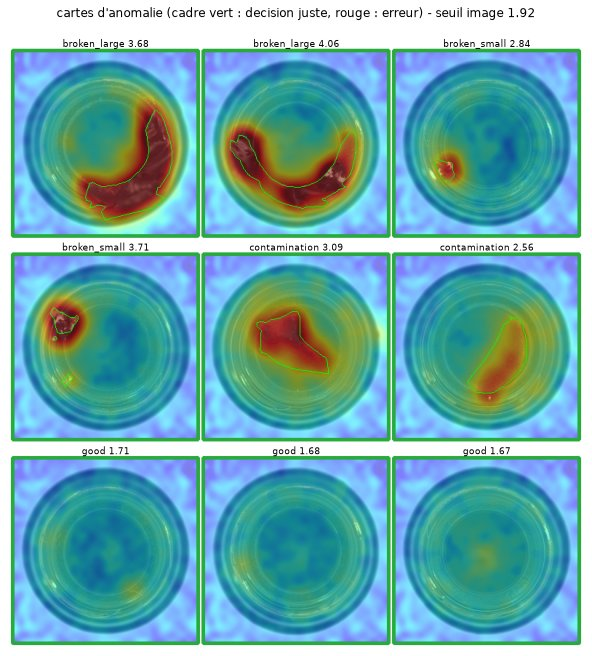

In [9]:
# dessine sur l'image le contour du masque de verite (vert par defaut) ; renvoie l'image annotee
def with_contour(rgb: np.ndarray, mask: np.ndarray, color: tuple[int, int, int] = (0, 255, 0)) -> np.ndarray:
    out = np.ascontiguousarray(rgb.copy())  # copie rangee d'un bloc en memoire (exige par les dessins OpenCV)
    # contours exterieurs des zones de defaut, simplifies (seulement les points utiles)
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, contours, -1, color, 1)  # trace tous les contours (-1), epaisseur 1 pixel
    return out  # image annotee


defects = test_df.index[test_labels == 1]  # positions des images a defaut du test
normals = test_df.index[test_labels == 0]  # positions des images normales du test
# 2 images par type de defaut + les 3 normales au score le plus haut (argsort de -score = tri decroissant)
chosen = list(test_df.loc[defects].groupby("defect_type").head(2).index) + list(normals[np.argsort(-test_scores[normals])[:3]])
viz.grid(  # grille des cartes du test
    [  # une image par cas choisi
        # carte d'anomalie fondue sur l'image (meme echelle pour toutes : 0 a 2 x seuil pixel), contour vert de la verite
        with_contour(viz.overlay_heatmap(test_images[i], test_maps[i], alpha=0.5, vmin=0.0, vmax=2 * thresholds["pixel"]), test_masks[i])
        for i in chosen  # pour chaque image choisie
    ],
    [f"{test_df.loc[i, 'defect_type']} {test_scores[i]:.2f}" for i in chosen],  # titres : type et score
    ncols=3,  # 3 images par ligne
    size=2.4,  # largeur de chaque colonne (pouces)
    borders=[bool((test_scores[i] > thresholds["image"]) == test_labels[i]) for i in chosen],  # cadre vert si decision juste, rouge sinon
    suptitle=f"cartes d'anomalie (cadre vert : decision juste, rouge : erreur) - seuil image {thresholds['image']:.2f}",  # titre
)

## Etape 9 - Hyperparametres : combien de memoire ? Glouton contre aleatoire

On reconstruit le modele avec plusieurs tailles de memoire, et avec un tirage aleatoire a taille
egale. Le seuil est recalibre a chaque fois sur la validation (jamais sur le test). Lecture :
la precision sature vite, la latence croit avec la memoire ; le glouton tient avec moins de
vecteurs que l'aleatoire.

,coreset,vecteurs,auroc_image,auroc_pixel,recall,false_alarm_rate,ms_par_image
0,glouton 0.5%,906,1.0000,0.9813,1.0,0.00,37.6
1,glouton 2.0%,3624,1.0000,0.9821,1.0,0.00,60.9
2,aleatoire 2.0%,3624,0.9992,0.9819,1.0,0.05,58.6


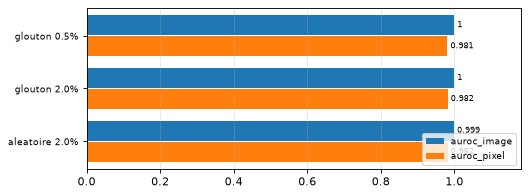

In [10]:
fractions = [0.005, MEMORY_FRACTION] if QUICK else [0.002, 0.005, 0.01, MEMORY_FRACTION, 0.05, 0.1]  # tailles de memoire essayees
variants = [("glouton", f) for f in fractions] + [("aleatoire", MEMORY_FRACTION)]  # coreset glouton a chaque taille + un tirage au hasard
rows = []  # une ligne de resultats par variante
for kind, fraction in variants:  # pour chaque variante (methode de selection, part gardee)
    n = max(1, int(fraction * len(bank)))  # nombre de vecteurs gardes
    if kind == "glouton":  # coreset glouton
        index = keep if fraction == MEMORY_FRACTION else greedy_coreset(bank, n, SEED)  # deja calcule pour 2 %, sinon on le calcule
    else:  # tirage aleatoire
        index = torch.randperm(len(bank), generator=torch.Generator().manual_seed(SEED))[:n]  # n vecteurs au hasard (graine fixe)
    # modele complet avec cette memoire
    candidate = AnomalyModel(PatchCore(features, bank[index].contiguous()), MapToScore(IMAGE_SIZE, SIGMA)).eval()
    v_scores, _ = score_images(candidate, x_val)  # scores des normales de validation (pour recalibrer le seuil)
    start = time.time()  # chrono du test
    t_scores, t_maps = score_images(candidate, x_test)  # scores et cartes du test
    elapsed = 1000 * (time.time() - start) / len(x_test)  # temps moyen par image (ms)
    m = anomaly_metrics(  # metriques du test pour cette memoire
        t_scores,  # scores du test
        t_maps,  # cartes du test
        test_masks,  # masques de verite
        test_labels,  # verite par image
        float(np.quantile(v_scores, IMAGE_QUANTILE)),  # seuil recalcule sur la validation (quantile 0,99) pour cette memoire
        test_df["defect_type"].to_numpy(),  # type de chaque image
    )
    rows.append(  # ajoute la ligne de cette variante
        {  # une ligne du tableau
            "coreset": f"{kind} {fraction:.1%}",  # nom de la variante (methode et pourcentage)
            "vecteurs": n,  # taille de la memoire
            "auroc_image": round(m["auroc_image"], 4),  # AUROC image
            "auroc_pixel": round(m["auroc_pixel"], 4),  # AUROC pixel
            "recall": round(m["recall"], 3),  # rappel
            "false_alarm_rate": round(m["false_alarm_rate"], 3),  # fausses alarmes
            "ms_par_image": round(elapsed, 1),  # vitesse
        }
    )
memory_study = pd.DataFrame(rows)  # tableau de l'etude
display(memory_study)  # l'affiche
viz.compare_runs(memory_study.set_index("coreset"), ["auroc_image", "auroc_pixel"])  # barres comparant les AUROC des variantes

## Etape 12 - Sauvegarder et exporter : exporter en ONNX, en un seul bloc

Extraction, memoire (un tenseur constant dans le graphe), distance, lissage et score : tout est
dans `model.onnx`. Le programme de production envoie une image dans [0, 1] et recoit la carte et
le score ; le seuil est dans la carte du modele (`model_card.json`, meme format que la toolbox).

Un export qui passe sans verification ne vaut rien : on compare ONNX et PyTorch sur de vraies
images, avec un lot (3) d'une autre taille que celui de l'export (2), ce qui teste aussi le lot
dynamique. Tolerance relative a l'ECHELLE de la sortie (une distance pres de 0 et un score de 2
n'ont pas la meme precision absolue).

In [11]:
model = model.eval().cpu()  # mode evaluation et retour sur CPU pour l'export
onnx_path = OUT / "model.onnx"  # fichier ONNX : le modele dans un format lisible sans PyTorch (production)
with warnings.catch_warnings():  # dans ce bloc, les avertissements sont geres a part ...
    warnings.simplefilter("ignore")  # ... et masques (l'export en produit beaucoup)
    torch.onnx.export(  # fait passer un exemple dans le modele, enregistre les operations et les ecrit au format ONNX
        model,  # modele complet : extraction, memoire, distance, lissage, score
        (x_val[:2],),  # exemple d'entree : un lot de 2 images de validation
        str(onnx_path),  # chemin du fichier a ecrire
        input_names=["input"],  # nom de l'entree dans le graphe ONNX
        output_names=["anomaly_map", "score"],  # noms des deux sorties
        dynamic_axes={"input": {0: "batch"}, "anomaly_map": {0: "batch"}, "score": {0: "batch"}},  # taille du lot (axe 0) libre partout
        opset_version=18,  # version du jeu d'operations ONNX
        dynamo=False,  # exporteur classique (par tracage), stable pour ce modele
    )
session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])  # charge le fichier ONNX dans onnxruntime (CPU)
batch = x_val[:3]  # lot de 3 : une autre taille que l'export, teste aussi le lot libre
with torch.no_grad():  # sans gradient : simple prediction
    torch_outputs = [t.numpy() for t in model(batch)]  # reponses PyTorch (carte, score)
onnx_outputs = session.run(None, {"input": batch.numpy()})  # reponses onnxruntime sur les memes images
report = {}  # ecart et echelle de chaque sortie
for name, t, o in zip(["anomaly_map", "score"], torch_outputs, onnx_outputs):  # pour chaque sortie : nom, PyTorch, ONNX
    diff, scale = float(np.abs(t - o).max()), float(np.abs(t).max())  # plus grand ecart, et ordre de grandeur des valeurs
    report[name] = {"max_abs_diff": diff, "scale": scale}  # note les deux
    # les deux reponses doivent concorder, avec une tolerance relative a l'echelle ; sinon arret
    assert diff <= 1e-4 + 1e-3 * scale, f"{name} : ecart ONNX / PyTorch {diff:.2e} pour une echelle {scale:.2e}"
print(f"ONNX verifie (lot de 3) : {report} | {onnx_path.stat().st_size / 1e6:.1f} Mo")  # bilan et taille du fichier


def latency_ms(fn, runs: int = 20) -> float:  # temps moyen d'un appel de fn, en millisecondes
    for _ in range(2):  # 2 appels de chauffe non chronometres ...
        fn()  # ... (le premier appel est toujours plus lent : allocations, caches)
    start = time.perf_counter()  # chrono precis
    for _ in range(runs):  # `runs` appels chronometres
        fn()  # un appel du modele
    return round(1000 * (time.perf_counter() - start) / runs, 2)  # duree moyenne en ms, arrondie a 2 decimales


one = x_val[:1]  # une seule image (lot de 1) : la latence vue par la production
with torch.no_grad():  # sans gradient
    latency = {  # latence des deux moteurs
        "torch_cpu_ms": latency_ms(lambda: model(one)),  # PyTorch sur CPU (lambda : petite fonction sans nom)
        "onnxruntime_cpu_ms": latency_ms(lambda: session.run(None, {"input": one.numpy()})),  # onnxruntime sur CPU
    }
print("latence (1 image) :", latency)  # affiche les latences

channels = int(x_train.shape[1])  # nombre de canaux des images (3 en couleur)
card = {  # carte du modele : tout ce que la production doit savoir pour l'utiliser
    "task": "anomaly",  # type de tache : detection d'anomalies
    "model_name": "patchcore_lite",  # nom du modele
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),  # date et heure de creation (UTC)
    "framework": {"torch": torch.__version__, "onnxruntime": ort.__version__},  # versions des bibliotheques
    "input": {  # description de l'entree attendue
        "name": "input",  # nom de l'entree dans le graphe ONNX
        "layout": "NCHW",  # ordre des axes : lot, canaux, hauteur, largeur
        "height": IMAGE_SIZE,  # hauteur en pixels
        "width": IMAGE_SIZE,  # largeur en pixels
        "channels": channels,  # nombre de canaux
        "color": "RGB" if channels == 3 else "GRAY",  # couleur ou gris
        "dtype": "float32",  # nombres a virgule sur 32 bits
        "scale": "divide by 255 (8 bits) or 65535 (16 bits)",  # mise a l'echelle [0, 1] a faire avant l'envoi
        "mean": [],  # vide : la normalisation ImageNet est deja dans le modele
        "std": [],  # vide aussi, meme raison
        "resize": "stretch",  # redimensionnement en etirant (proportions non conservees)
        "letterbox_pad_value": None,  # pas de letterbox (bandes ajoutees pour garder les proportions)
        "dynamic_batch": True,  # taille de lot libre
        "read_color": COLOR,  # mode de lecture de l'image
    },
    "preprocess": [{"name": "resize", "size": IMAGE_SIZE, "interpolation": "auto"}],  # pretraitement : resize, interpolation automatique
    "outputs": [  # description des deux sorties
        {  # sortie 1 : la carte
            "name": "anomaly_map",  # son nom
            "shape": ["batch", 1, IMAGE_SIZE, IMAGE_SIZE],  # sa forme : lot, 1 canal, hauteur, largeur
            "description": "carte d'anomalie lissee (plus haut = plus anormal)",  # ce qu'elle contient
        },
        {"name": "score", "shape": ["batch"], "description": "score image ; anomalie si score > thresholds.image"},  # sortie 2 : le score
    ],
    "class_names": [],  # pas de classes : seulement normal ou anomalie
    "thresholds": thresholds,  # seuils image et pixel calibres sur la validation
    # regle de decision et origine du seuil
    "postprocess": {"decision": "score > thresholds.image", "calibration": f"quantile {IMAGE_QUANTILE} des normales de validation"},
    # metriques principales du test, arrondies a 4 decimales
    "metrics": {k: round(v, 4) for k, v in metrics.items() if k in ("auroc_image", "auroc_pixel", "recall", "false_alarm_rate", "f1")},
    "latency_ms": latency,  # latences mesurees
    "files": {"onnx": "model.onnx"},  # fichier du modele, a cote de la carte
    "notes": f"PatchCore ecrit dans le notebook 14 ; memoire {len(memory)} x {memory.shape[1]} ; verification ONNX : {report}",  # note
}
(OUT / "model_card.json").write_text(json.dumps(card, indent=2), encoding="utf-8")  # ecrit la carte en JSON lisible
print("ecrit :", sorted(p.name for p in OUT.iterdir()))  # liste les fichiers du dossier de sortie

ONNX verifie (lot de 3) : {'anomaly_map': {'max_abs_diff': 0.00011619925498962402, 'scale': 1.6380271911621094}, 'score': {'max_abs_diff': 2.7418136596679688e-06, 'scale': 1.6380271911621094}} | 16.7 Mo


latence (1 image) : {'torch_cpu_ms': 41.39, 'onnxruntime_cpu_ms': 36.85}
ecrit : ['model.onnx', 'model_card.json', 'split.csv']


## Resultats

Reference : la recette de production `patchcore_lite_bottle` (meme decoupage, memes reglages)
donne AUROC image 1,000, AUROC pixel 0,982, rappel 1,000 et 0 fausse alarme.

In [12]:
results = pd.DataFrame(  # tableau de comparaison notebook / recette
    [  # deux lignes
        # ligne 1 : ce notebook (** recopie ses 5 metriques principales, arrondies)
        {"source": "notebook 14", **{k: round(metrics[k], 4) for k in ("auroc_image", "auroc_pixel", "recall", "false_alarm_rate", "f1")}},
        {  # ligne 2 : la recette de reference
            "source": "recette patchcore_lite_bottle",  # description
            "auroc_image": 1.0,  # AUROC image obtenu par la recette
            "auroc_pixel": 0.982,  # AUROC pixel
            "recall": 1.0,  # rappel
            "false_alarm_rate": 0.0,  # fausses alarmes
            "f1": 1.0,  # F1
        },
    ]
)
display(results)  # affiche le tableau

,source,auroc_image,auroc_pixel,recall,false_alarm_rate,f1
0,notebook 14,1.0,0.9821,1.0,0.0,1.0
1,recette patchcore_lite_bottle,1.0,0.9820,1.0,0.0,1.0


## Adapter a tes donnees

- Rangement MVTec (train/good, test/<type>, ground_truth) : changer `DATA_DIR` et c'est tout.
- Autre rangement : ecrire un `catalog` avec les colonnes path, label (good / defect),
  defect_type, mask_path (vide si pas de masque) et split (train pour les normales d'
  apprentissage, test pour le reste), puis garder `anomaly_split`. Sans masques, l'AUROC pixel
  n'est pas calculable : retirer la ligne correspondante.
- Acier en niveaux de gris : `COLOR = "gray"` (copie sur 3 canaux dans le modele).
- Beaucoup d'images d'entrainement (plus de 500) : `MEMORY_FRACTION = 0.005` ; le coreset garde
  la couverture, la latence reste basse.
- Defauts tres petits : `IMAGE_SIZE` plus grand, ou des tuiles (une piece = plusieurs images).
- Moins de fausses alarmes : `IMAGE_QUANTILE = 0.995`, au prix du rappel, et toujours sur la
  validation.

## Passer en production

La meme experience en mode production (`recipes/anomaly/configs/patchcore_lite_bottle.yaml`) :

```yaml
data: {root: data/raw/mvtec_bottle, layout: mvtec}
normal_labels: [good]
split: {file: outputs/anomaly/bottle_split.csv, val_fraction: 0.15}
preprocess: [{name: resize, size: 256}]
scoring: {gaussian_sigma: 4.0, image_score: max, image_quantile: 0.99}
method: patchcore_lite
patchcore_lite: {layers: [layer2, layer3], memory_fraction: 0.02, coreset: greedy}
runtime: {output_dir: outputs/anomaly/patchcore_lite_bottle}
```

```
python recipes/anomaly/scripts/run.py --config recipes/anomaly/configs/patchcore_lite_bottle.yaml
python -m vtb.serve --model outputs/notebooks/14_anomalies_patchcore    # le modele du notebook, servi tel quel
```

Controle : le predicteur de production (`vtb.serve`, sans PyTorch : numpy, OpenCV,
onnxruntime) relit le dossier exporte par CE notebook et doit rendre les memes scores ; le
decoupage doit etre celui de la recette.

In [13]:
from vtb.serve.predictor import OnnxPredictor  # noqa: E402 - production seulement dans cette section (predicteur sans PyTorch)

predictor = OnnxPredictor(OUT)  # charge le modele ONNX et sa carte depuis le dossier exporte
picked = list(range(0, len(test_df), max(1, len(test_df) // 8)))[:8]  # 8 images du test reparties regulierement
# ecart de score entre le predicteur de production (depuis le fichier image brut) et le notebook, image par image
gaps = [abs(predictor(read_image(test_df.loc[i, "path"], predictor.color))["score"] - float(test_scores[i])) for i in picked]
print(f"predicteur de production : ecart max des scores {max(gaps):.2e} sur {len(picked)} images de test")  # plus grand ecart
assert max(gaps) < 1e-3 * max(1.0, float(np.abs(test_scores).max()))  # tolerance : 0,1 % du plus grand score (au moins 0,001)
decisions = [predictor(read_image(test_df.loc[i, "path"], predictor.color))["anomaly"] for i in picked]  # decisions de production
assert decisions == [bool(test_scores[i] > thresholds["image"]) for i in picked]  # doivent etre celles du notebook, image par image

recipe_split = Path("outputs/anomaly/bottle_split.csv")  # decoupage ecrit par la recette
if recipe_split.exists():  # si la recette a deja ete lancee
    theirs = pd.read_csv(recipe_split, keep_default_na=False).set_index("path")["split"]  # partie de chaque image selon la recette
    ours = split.set_index("path")["split"]  # partie de chaque image selon ce notebook
    # identique si chaque image est dans la meme partie (reindex aligne les deux tableaux par chemin)
    print("decoupage identique a la recette :", bool((theirs.reindex(ours.index) == ours).all()))
else:  # sinon (recette pas encore lancee)
    print("decoupage de la recette absent (lancer la recette pour comparer)")  # le signale

predicteur de production : ecart max des scores 1.19e-06 sur 8 images de test


decoupage identique a la recette : True


## Pour aller plus loin

- `15_anomalies_anomalib` : PaDiM, STFPM, FastFlow avec le meme protocole, et PatchCore
  d'anomalib (meme methode, implementation de reference).
- `13_anomalies_autoencodeur` : pourquoi la reconstruction echoue sur les textures, la ou
  PatchCore tient (Magnetic Tile : AUROC image 0,965 pour PatchCore, 0,54 pour l'auto-encodeur).
- Tuiles sur une grande image : decouper, scorer chaque tuile, recoller les cartes (maximum).